# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

Обучал на каггле, Tesla T4. Основная модель YOLO26n.

Датасет с фркутами Fruit Images for Object Detection, лицензия CC0. Выполнил всё, кроме бонуса 6.1. [Датасет на Kaggle](https://www.kaggle.com/datasets/mbkinaci/fruit-images-for-object-detection)

Настройки экспериментов использовал шаблонные из ДЗ + по документации YOLO подбирал

In [7]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.11.0+cu130, device: Tesla T4


In [8]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [9]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    device = kw.pop('device', DEVICE)
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=device, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [10]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
MODEL_INFO = dict(
    ultralytics=ultralytics.__version__,
    weights=weights_path.name,
    sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    size_mb=weights_path.stat().st_size / 1_000_000,
    params=sum(p.numel() for p in model_coco.model.parameters()),
    n_classes_coco=len(model_coco.names),
)

sample_image = np.random.default_rng(SEED).integers(0, 256, (IMGSZ, IMGSZ, 3), dtype=np.uint8)
predict_args = dict(imgsz=IMGSZ, device=DEVICE, verbose=False)
for _ in range(3):
    model_coco.predict(sample_image, **predict_args)

if torch.cuda.is_available():
    torch.cuda.synchronize(DEVICE)
start = time.perf_counter()
n_runs = 10
for _ in range(n_runs):
    model_coco.predict(sample_image, **predict_args)
if torch.cuda.is_available():
    torch.cuda.synchronize(DEVICE)
MODEL_INFO['latency_ms'] = 1000 * (time.perf_counter() - start) / n_runs

In [11]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.544453,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 13.07187600000077}

**Ответ:**

У меня в датасете в основном крупные изображения фруктов, всего 192 изображения в train, поэтому решил, что хватит компактной YOLO26n. При входе 640 × 640 у YOLO26n и YOLO26s соответственно 2,4 и 9,5 млн параметров после оптимизации для инференса, 40,1% и 47,8% COCO mAP50–95 в режиме end-to-end, 1,7 и 2,5 мс на T4. В моём прогоне на T4 полный вызов `predict` для YOLO26n занял 13,07 мс.

Код и веса Ultralytics доступны по лецензии AGPL-3.0. Это значит, что надо сохранять лицензионные уведомления и предоставлять соответствующий исходный код, если я распространяю работу.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [12]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    return dict(
        backbone=sum(p.numel() for p in layers[:n_backbone].parameters()),
        neck=sum(p.numel() for p in layers[n_backbone:-1].parameters()),
        head=sum(p.numel() for p in layers[-1].parameters()),
    )


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    feat_shapes = []

    def collect_shapes(module, inputs):
        feat_shapes.extend(tuple(feature.shape) for feature in inputs[0])

    dummy = next(det_model.parameters()).new_zeros((1, 3, imgsz, imgsz))
    was_training = det_model.training
    hook = det_model.model[-1].register_forward_pre_hook(collect_shapes)
    try:
        det_model.eval()
        with torch.inference_mode():
            out = det_model(dummy)
    finally:
        hook.remove()
        det_model.train(was_training)
    return feat_shapes, out


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [13]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [14]:
print('выход модели:', shapes(out))

выход модели: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:**

Backbone извлекает признаки, а neck объединяет пространственные детали и признаки высокого уровня на трёх масштабах со страйдами 8, 16 и 32. Голова Detect предсказывает четыре координаты бокса и 80 оценок классов COCO для каждой точки. Схема называется anchor-free, потому что у нас нет заранее заданных размеров боксов, они предсказыываются относительно точек сетки. При входе 640 получаем $80^2 + 40^2 + 20^2 = 8400$ точек, т.к. страйды заданы как 8, 16, 32.

`one2many` обучается на нескольких положительных позициях для объекта, после чего NMS убирает дубли. `one2one` сопоставляет объекту одну позицию и позволяет предсказывать без NMS при `nms=False`. Из 2 572 280 параметров на backbone приходится 53%, на neck — 35%, на голову — 12%.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [15]:
DATASET_NAME = 'Fruit Images for Object Detection, https://www.kaggle.com/datasets/mbkinaci/fruit-images-for-object-detection, CC0'
CLASSES = ['apple', 'banana', 'orange']
class_ids = {name: i for i, name in enumerate(CLASSES)}

dataset_root = Path('/kaggle/input/datasets/mbkinaci/fruit-images-for-object-detection')


def read_voc_split(split_dir):
    image_paths = sorted(split_dir.glob('*.jpg'))

    recs = []
    cleanup = Counter(clipped=0, removed=0)
    for image_path in image_paths:
        with Image.open(image_path) as image:
            width, height = image.size
        annotation = ET.parse(image_path.with_suffix('.xml')).getroot()
        bounds = [width, height, width, height]
        boxes, labels = [], []
        for obj in annotation.findall('object'):
            bbox = obj.find('bndbox')
            box = [float(bbox.findtext(coord)) for coord in ('xmin', 'ymin', 'xmax', 'ymax')]
            clipped = np.clip(box, 0, bounds)
            cleanup['clipped'] += int(np.any(clipped != box))
            x1, y1, x2, y2 = clipped
            if not (x1 < x2 and y1 < y2):
                cleanup['removed'] += 1
                continue
            boxes.append(clipped)
            labels.append(class_ids[obj.findtext('name').strip().lower()])

        recs.append(dict(image=image_path, width=width, height=height,
                         boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                         labels=np.asarray(labels, dtype=np.int64)))
    return recs, cleanup


original_train, train_cleanup = read_voc_split(dataset_root / 'train_zip' / 'train')
test_records, test_cleanup = read_voc_split(dataset_root / 'test_zip' / 'test')
order = np.random.default_rng(SEED).permutation(len(original_train))
n_val = round(0.2 * len(original_train))
records = {
    'train': [original_train[i] for i in order[n_val:]],
    'val': [original_train[i] for i in order[:n_val]],
    'test': test_records,
}

for split, cleanup in [('исходный train', train_cleanup), ('test', test_cleanup)]:
    print(f'{split}: боксов за границей {cleanup["clipped"]}, удалено после обрезки {cleanup["removed"]}')

исходный train: боксов за границей 0, удалено после обрезки 0
test: боксов за границей 0, удалено после обрезки 0


In [16]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 192, 'val': 48, 'test': 60}

train: 192 изображений, 380 объектов
{'apple': 127, 'banana': 140, 'orange': 113}
Объектов на изображение: среднее 1.98, медиана 1, максимум 9
val: 48 изображений, 85 объектов
{'apple': 29, 'banana': 29, 'orange': 27}
Объектов на изображение: среднее 1.77, медиана 1, максимум 7
test: 60 изображений, 117 объектов
{'apple': 35, 'banana': 40, 'orange': 42}
Объектов на изображение: среднее 1.95, медиана 1, максимум 5


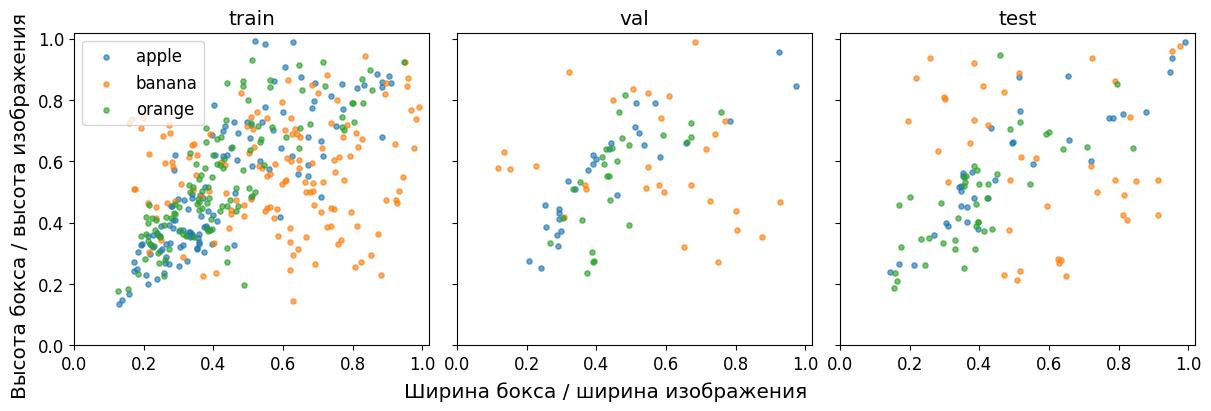

In [17]:
fig, axes = plt.subplots(1, len(records), figsize=(12, 4), sharex=True, sharey=True, layout='constrained')
for (split, recs), ax in zip(records.items(), axes):
    labels = np.concatenate([r['labels'] for r in recs])
    counts = Counter(labels)
    per_image = np.array([len(r['labels']) for r in recs])
    print(f'{split}: {len(recs)} изображений, {len(labels)} объектов')
    print({name: counts[i] for i, name in enumerate(CLASSES)})
    print(f'Объектов на изображение: среднее {per_image.mean():.2f}, '
          f'медиана {np.median(per_image):.0f}, максимум {per_image.max()}')

    sizes = np.concatenate([(r['boxes'][:, 2:] - r['boxes'][:, :2]) / [r['width'], r['height']]
                            for r in recs])
    for i, name in enumerate(CLASSES):
        class_sizes = sizes[labels == i]
        ax.scatter(class_sizes[:, 0], class_sizes[:, 1], s=14, alpha=0.65, label=name)
    ax.set(title=split, xlim=(0, 1.02), ylim=(0, 1.02))

axes[0].legend()
fig.supxlabel('Ширина бокса / ширина изображения')
fig.supylabel('Высота бокса / высота изображения')
plt.show()

**Ответ:**

В датасете 300 фото яблок, бананов и апельсинов с VOC XML, лицензия CC0. Оставил исходные 60 `test` и разделил 240 `train` с `seed=0` на 192 `train` и 48 `val`.

В `train` 127 яблок, 140 бананов и 113 апельсинов, поэтому дисбаланс умеренный. По медиане 1 объект на фото, максимум есть девять, отдельные боксы занимают около 15–20% ширины кадра, большинство крупнее. Боксов нулевой площади или за границей нет. У части фруктов пропущены боксы, например у зелёных яблок и очищенного банана на `banana_52.jpg`. На `banana_61.jpg` яблоко размечено как `banana`, а на `banana_70.jpg` рамка обрезает концы банана.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [18]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    lines = []
    for (x1, y1, x2, y2), label in zip(np.asarray(boxes, dtype=float), labels):
        cx = (x1 + x2) / (2 * width)
        cy = (y1 + y2) / (2 * height)
        w = (x2 - x1) / width
        h = (y2 - y1) / height
        lines.append(f'{int(label)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}')
    return '\n'.join(lines)


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    boxes, labels = [], []
    for line in text.splitlines():
        if not line.strip():
            continue
        label, *coords = line.split()
        cx, cy, w, h = map(float, coords)
        boxes.append([(cx - w / 2) * width, (cy - h / 2) * height,
                      (cx + w / 2) * width, (cy + h / 2) * height])
        labels.append(int(label))
    return np.asarray(boxes, dtype=np.float32).reshape(-1, 4), np.asarray(labels, dtype=np.int64)

In [19]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [20]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    images_dir = YOLO_ROOT / 'images' / split
    labels_dir = YOLO_ROOT / 'labels' / split
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)
    for rec in recs:
        image_path = Path(rec['image'])
        shutil.copyfile(image_path, images_dir / image_path.name)
        labels_text = to_yolo(rec['boxes'], rec['labels'], rec['width'], rec['height'])
        (labels_dir / f'{image_path.stem}.txt').write_text(labels_text, encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /kaggle/working/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: apple
  1: banana
  2: orange



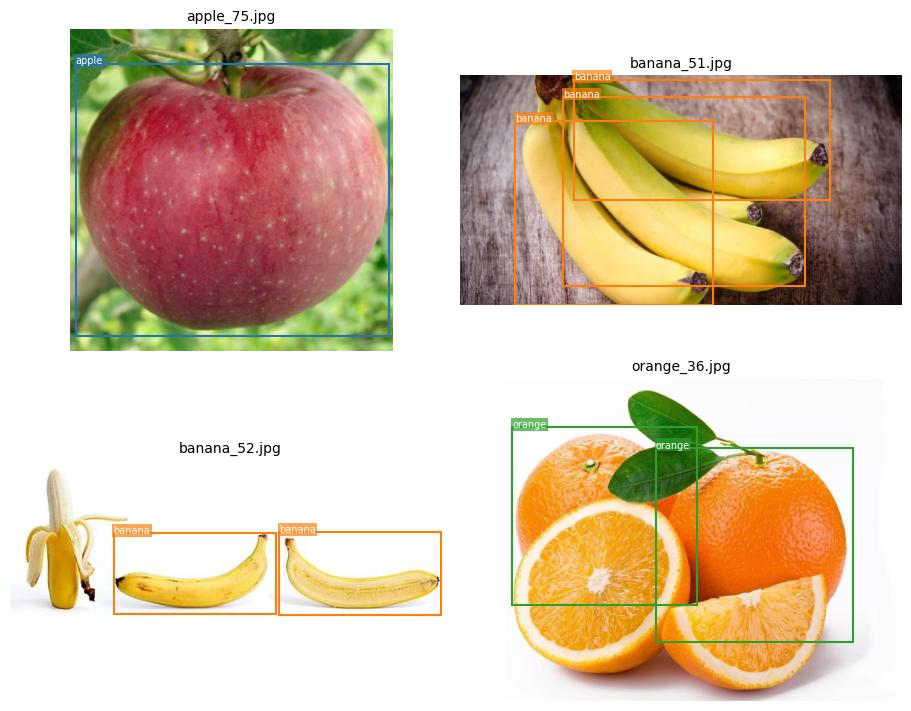

In [21]:
val_recs = splits['val']
indices = np.random.default_rng(SEED).choice(len(val_recs), size=4, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout='constrained')
for ax, i in zip(axes.flat, indices):
    name = Path(val_recs[i]['image']).name
    image_path = YOLO_ROOT / 'images' / 'val' / name
    label_path = YOLO_ROOT / 'labels' / 'val' / f'{image_path.stem}.txt'
    with Image.open(image_path) as image:
        boxes, labels = from_yolo(label_path.read_text(encoding='utf-8'), *image.size)
        draw_boxes(ax, image.convert('RGB'), boxes, labels, CLASSES, title=name)
plt.show()

**Ответ:**

Проверка `xyxy → YOLO → xyxy` сравнивает исходные и восстановленные координаты (округление допустимо) и проверяет классы. Из пропущенных проблем, например, можно менять оси в обеих функциях, тогда тест пройдет, а результат неверный. Только на картинке можно заметить сдвиги, растяжения или разметку от другого изображения.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [22]:
coco_to_fruit = np.full(len(model_coco.names), -1, dtype=np.int64)
for coco_id, name in model_coco.names.items():
    if name in CLASSES:
        coco_to_fruit[coco_id] = CLASSES.index(name)

coco_preds = []
for pred in predict_records(model_coco, records[FINAL_SPLIT]):
    labels = coco_to_fruit[pred['labels']]
    keep = labels >= 0
    coco_preds.append(dict(boxes=pred['boxes'][keep], labels=labels[keep], scores=pred['scores'][keep]))

coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'COCO YOLO на {FINAL_SPLIT}: mAP50 = {coco_map50:.4f}')
print('AP50 по классам:', dict(zip(CLASSES, coco_aps)))

COCO YOLO на test: mAP50 = 0.6518
AP50 по классам: {'apple': 0.7447650877650878, 'banana': 0.5894140850338329, 'orange': 0.6210764932273392}


In [23]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    with Image.open(image_path) as image:
        hsv = np.asarray(image.convert('RGB').convert('HSV'))
    hue, saturation, value = hsv.transpose(2, 0, 1)
    colorful = (saturation >= min_saturation) & (value >= 45)
    color_masks = {
        'apple': (hue < 10) | (hue >= 245) | ((hue >= 46) & (hue <= 100)),
        'banana': (hue >= 29) & (hue < 46),
        'orange': (hue >= 10) & (hue < 29),
    }

    boxes, labels, scores = [], [], []
    for label, name in enumerate(CLASSES):
        regions, _ = ndimage.label(color_masks[name] & colorful)
        areas = np.bincount(regions.ravel())
        for region_id, (y, x) in enumerate(ndimage.find_objects(regions), start=1):
            score = areas[region_id] / hue.size
            if score >= 0.005:
                boxes.append([x.start, y.start, x.stop, y.stop])
                labels.append(label)
                scores.append(score)
    return dict(boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                labels=np.asarray(labels, dtype=np.int64), scores=np.asarray(scores, dtype=np.float32))

In [24]:
train_scores = {}
for min_saturation in (55, 80, 105):
    train_preds = [heuristic_detect(r['image']) for r in train_recs]
    train_scores[min_saturation], _ = evaluate_map50(train_preds, train_recs, len(CLASSES))
min_saturation = max(train_scores, key=train_scores.get)
print(f'mAP50 на train по порогам насыщенности: {train_scores}; выбран {min_saturation}')

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


mAP50 на train по порогам насыщенности: {55: 0.3170054188231019, 80: 0.33412351742898244, 105: 0.352359813249229}; выбран 105


In [25]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.65175188867542,
 'heuristic_map50': 0.32908312715946836,
 'heuristic_ap50_per_class': {'apple': 0.3887718371437179,
  'banana': 0.37031932773109244,
  'orange': 0.22815821660359475}}

**Ответ:**

Исходная YOLO26n дала 65,18% mAP50 на `test`. Все три фрукта входят в COCO, поэтому модель уже умеет их распознавать. Хуже всего она находила бананы с AP50 58,94%.

Цветовая эвристика дала 32,91% mAP50. Лучше всего она сработала на яблоках (AP50 38,88%) и бананах (37,03%), хуже всего — на апельсинах (22,82%). Думаю, что отличить яблоки и бананы проще из-за их цвета, а с апельсинами труднее, т.к. порог HSV чувствителен к освещению и похожим оттенкам.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [26]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [27]:
TRAIN_ARGS = dict(
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
    optimizer='AdamW', lr0=0.001, patience=12, val=True,
    fliplr=0.5, flipud=0.0, hsv_h=0.0, hsv_s=0.3, hsv_v=0.25,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.3, hsv_v=0.25, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ada

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      2.68G       1.37      1.145    0.02373         74        640: 100% ━━━━━━━━━━━━ 12/12 6.6it/s 1.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 7.0it/s 0.3s0.6s
                   all         48         85      0.528      0.577      0.581      0.386

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      2.68G      1.299      1.094    0.02174         64        640: 100% ━━━━━━━━━━━━ 12/12 6.6it/s 1.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 7.3it/s 0.3s0.6s
                   all         48         85      0.668      0.723        0.7      0.435

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/60      2.68G      1.312      1.053    0.02214         72        640: 100% ━━━━━━━━━━━━ 12/12 6.9it/s 1.7s0.1s
                 Class     Images  Instances  

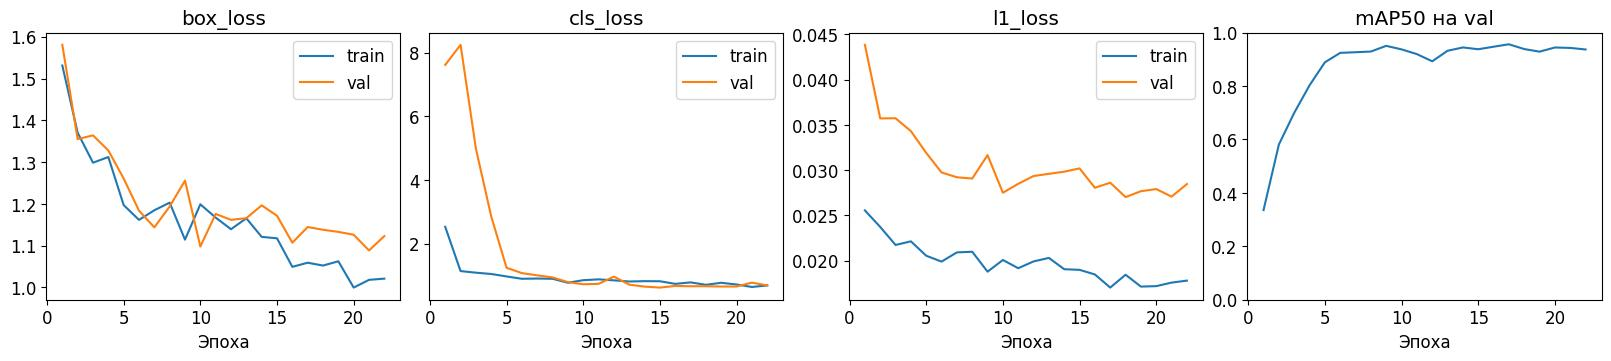

In [28]:
history = read_results(run_dir)
epochs = history['epoch']
loss_names = sorted({key.split('/', 1)[1] for key in history
                     if key.startswith(('train/', 'val/')) and key.endswith('_loss')})
n_plots = len(loss_names) + 1
fig, axes = plt.subplots(1, n_plots, figsize=(4 * n_plots, 3.5), layout='constrained')
for ax, loss in zip(axes, loss_names):
    for split in ('train', 'val'):
        key = f'{split}/{loss}'
        if key in history:
            ax.plot(epochs, history[key], label=split)
    ax.set(title=loss, xlabel='Эпоха')
    ax.legend()

axes[-1].plot(epochs, history['metrics/mAP50(B)'])
axes[-1].set(title='mAP50 на val', xlabel='Эпоха', ylim=(0, 1))
plt.show()

**Ответ:**

Из параметров выбрал уже заданные в дз `imgsz=640` и `batch=16`, который поместился в память T4. Взял базовый AdamW с шагом `lr0=0.001`.

Задал до 60 эпох с `patience=12`. Лучший `best.pt` выбран на 10-й эпохе, а прогон остановился на 22-й и занял 80 с. `train/box_loss` снизился с 1,53 до 1,02, `val/box_loss` — с 1,58 до 1,12. Валидационные потери колебались к концу без устойчивого роста, а 12 эпох после лучшего чекпойнта хватило, чтобы увидеть плато по критерию ранней остановки. Поэтому обучение можно счтать корректным

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [29]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(kw.pop('data', DATA_YAML)), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2046.0±1121.8 MB/s, size: 68.5 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 48 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 16.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7it/s 1.1s0.8s
                   all         48         85      0.875      0.905      0.936      0.678
Speed: 2.1ms preprocess, 8.6ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /kaggle/working/runs_hw2/best_val
val {'precision': 0.8749, 'recall': 0.9046, 'map50': 0.9364, 'map50_95': 0.6776}
apple {'precision': 0.8589567548496196, 'recall': 1.0, 'map50': 0.9765844155844156, 'map50_95': 0.772615698914612}
banana {'precision': 0.8530133569654822, 'recall': 0.862068965517

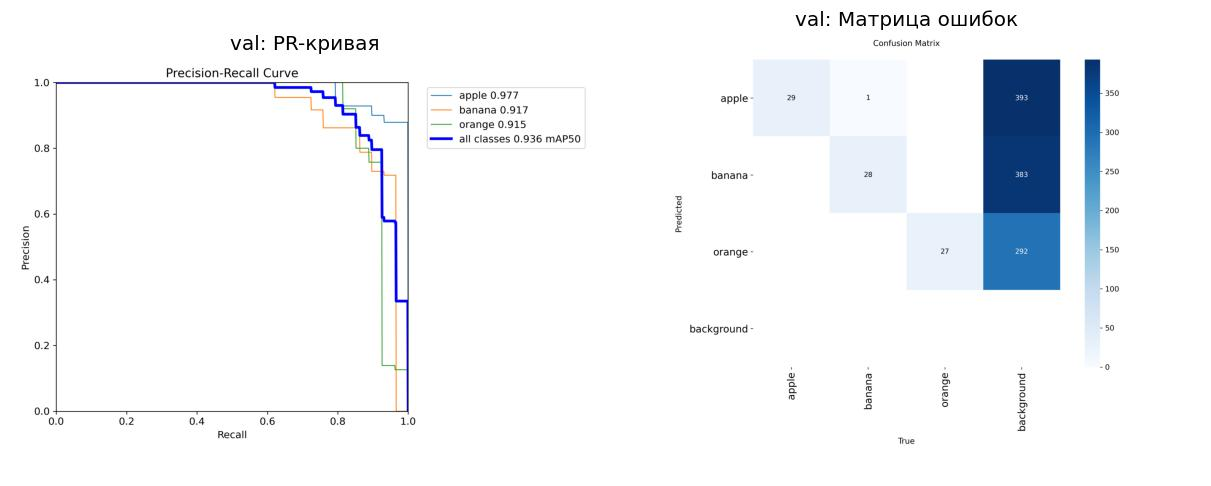

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1894.9±1283.5 MB/s, size: 73.3 KB)
val: Scanning /kaggle/working/data/yolo/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.1Kit/s 0.1s
val: New cache created: /kaggle/working/data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.5it/s 1.1s0.4s
                   all         60        117      0.855      0.788      0.886      0.599
Speed: 1.3ms preprocess, 7.3ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /kaggle/working/runs_hw2/best_test
test {'precision': 0.8554, 'recall': 0.788, 'map50': 0.8864, 'map50_95': 0.5987}
apple {'precision': 0.8138178554855486, 'recall': 0.8743996114803324, 'map50': 0.876260871499235, 'map50_95': 0.67748

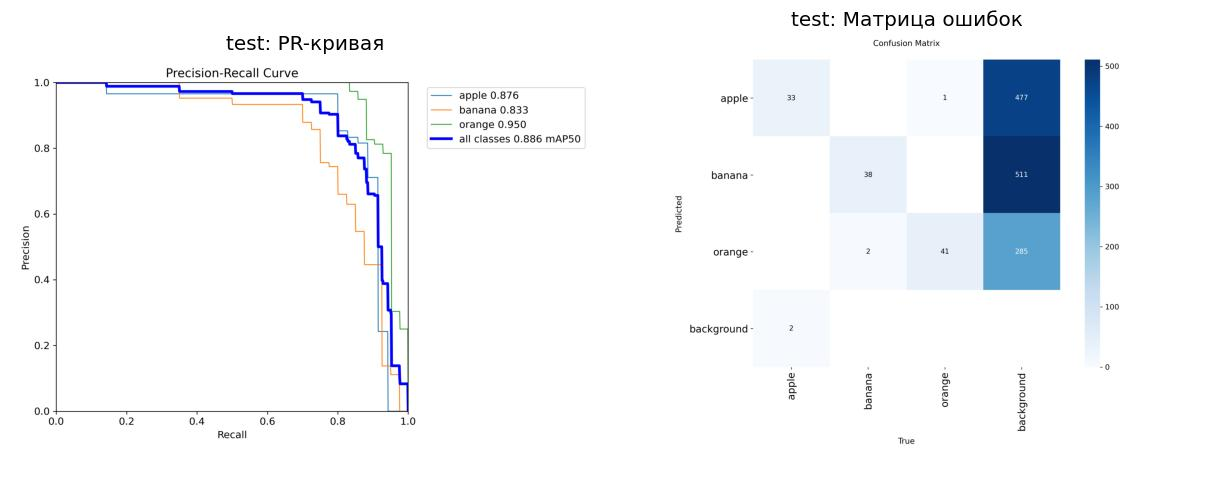

test: mAP50 через evaluate_map50 = 0.8810, разница с Ultralytics = -0.0054


In [30]:
metric_names = ('precision', 'recall', 'map50', 'map50_95')
metrics_by_split = {}
for split in ('val', 'test'):
    name = f'best_{split}'
    box_metrics = val_metrics(best, split, name, plots=True).box
    summary = dict(zip(metric_names, map(float, box_metrics.mean_results())))
    per_class = dict.fromkeys(CLASSES)
    for i, class_id in enumerate(box_metrics.ap_class_index):
        per_class[CLASSES[class_id]] = dict(zip(metric_names, map(float, box_metrics.class_result(i))))
    metrics_by_split[split] = dict(summary, per_class=per_class)

    print(split, {key: round(value, 4) for key, value in summary.items()})
    for class_name, values in per_class.items():
        print(class_name, values)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
    plots = [('BoxPR_curve.png', 'PR-кривая'), ('confusion_matrix.png', 'Матрица ошибок')]
    for ax, (filename, title) in zip(axes, plots):
        plot_path = RUNS / name / filename
        ax.imshow(plt.imread(plot_path))
        ax.set_title(f'{split}: {title}')
        ax.axis('off')
    plt.show()

FINAL = metrics_by_split[FINAL_SPLIT]
final_preds = predict_records(best, records[FINAL_SPLIT])
check_map50, _ = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'{FINAL_SPLIT}: mAP50 через evaluate_map50 = {check_map50:.4f}, '
      f'разница с Ultralytics = {check_map50 - FINAL["map50"]:+.4f}')

In [31]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'precision': 0.8554, 'recall': 0.788, 'map50': 0.8864, 'map50_95': 0.5987}

**Ответ:**

На `test` хуже всего результат по бананам — AP50–95 49,55% на 40 объектах. Вытянутая форма и перекрытия, которые видны на примерах, могут затруднять точную локализацию. В матрице ошибок строка `background` показывает пропуски, столбец `background` — лишние предсказания.

mAP50–95 составил 59,87% при mAP50 88,64%, потому что на более строгих порогах IoU даже небольшое смещение бокса ухудшает результат. `evaluate_map50` дал 88,10%. Разницу в 0,54 п. п. могут объяснить разные правила сопоставления боксов и вычисления площади под PR-кривой.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [32]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.maximum(bottom_right - top_left, 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    gt_labels = np.asarray(gt['labels'])
    matched = np.zeros(len(gt_labels), dtype=bool)
    covered = np.zeros(len(gt_labels), dtype=bool)
    categories = ['background'] * len(pred['labels'])
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        overlaps = ious[i]
        same_class = gt_labels == pred['labels'][i]
        high_iou = overlaps >= iou_hit
        rules = (
            ('tp', same_class & high_iou & ~matched),
            ('class', ~same_class & high_iou),
            ('localization', same_class & ~matched & (overlaps >= iou_loc) & ~high_iou),
        )
        for category, mask in rules:
            candidates = np.flatnonzero(mask)
            if len(candidates):
                j = candidates[overlaps[candidates].argmax()]
                categories[i] = category
                covered[j] = True
                if category == 'tp':
                    matched[j] = True
                break
    return categories, np.flatnonzero(~covered).tolist()

In [33]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


val, conf ≥ 0.25
tp: 73 (84.9%)
class: 0 (0.0%)
localization: 5 (5.8%)
background: 8 (9.3%)
missed: 9 (10.6%)
apple {'tp': 28, 'class': 0, 'localization': 0, 'background': 4, 'missed': 1}
banana {'tp': 22, 'class': 0, 'localization': 4, 'background': 2, 'missed': 5}
orange {'tp': 23, 'class': 0, 'localization': 1, 'background': 2, 'missed': 3}


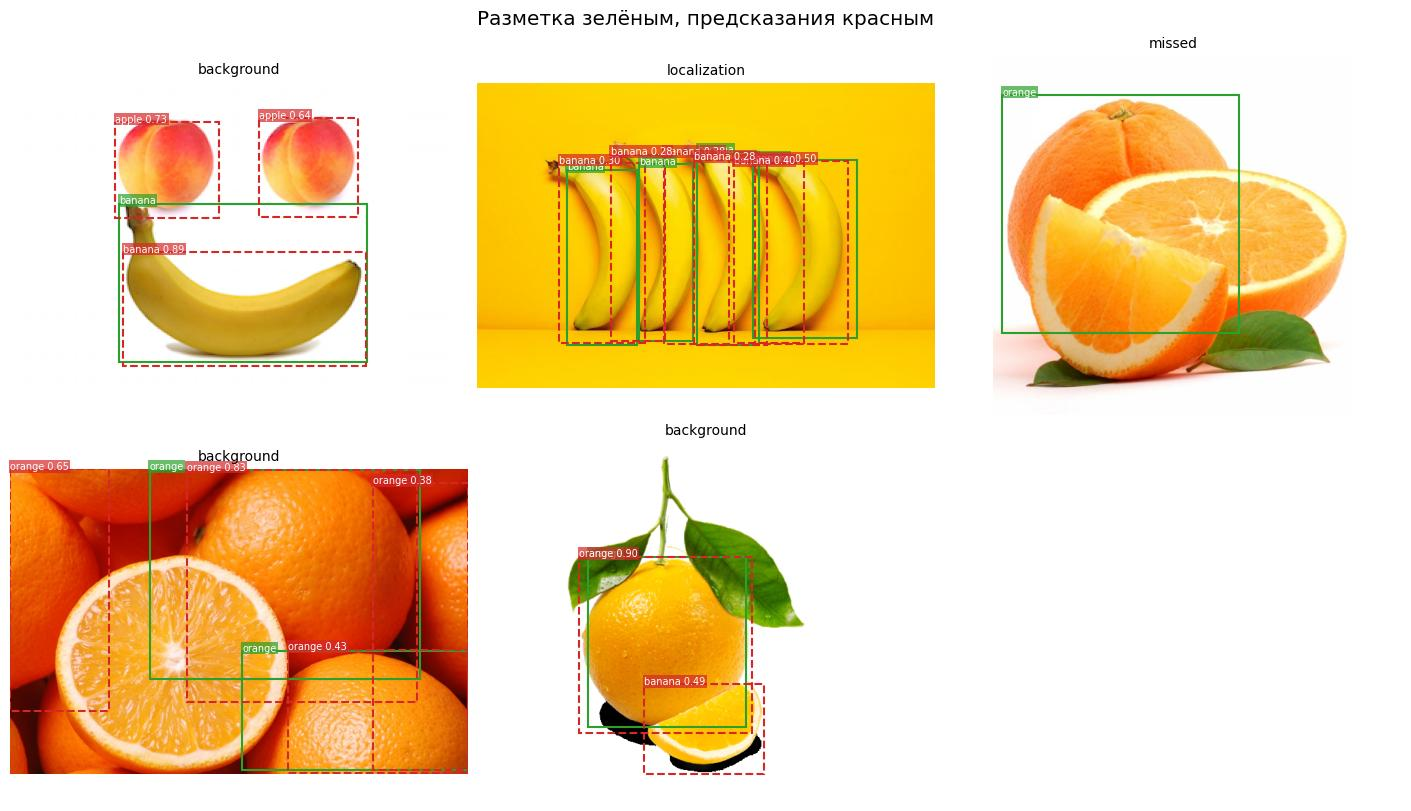

In [34]:
val_recs = records['val']
val_preds = predict_records(best, val_recs, conf=CONF_ERRORS)
errors_by_class = {name: Counter() for name in CLASSES}
error_examples = []
first_example = {}
for rec, pred in zip(val_recs, val_preds):
    categories, missed = categorize_predictions(pred, rec)
    for category, label in zip(categories, pred['labels']):
        errors_by_class[CLASSES[label]][category] += 1
    for i in missed:
        errors_by_class[CLASSES[rec['labels'][i]]]['missed'] += 1

    image_errors = set(categories) - {'tp'}
    if missed:
        image_errors.add('missed')
    if image_errors:
        for category in image_errors:
            first_example.setdefault(category, len(error_examples))
        error_examples.append((rec, pred, image_errors))

ERRORS = {category: sum(counts[category] for counts in errors_by_class.values()) for category in ERROR_TYPES}
n_predictions = sum(len(pred['labels']) for pred in val_preds)
n_objects = sum(len(rec['labels']) for rec in val_recs)
print(f'val, conf ≥ {CONF_ERRORS}')
for category, count in ERRORS.items():
    total = n_objects if category == 'missed' else n_predictions
    share = f'{count / total:.1%}' if total else '—'
    print(f'{category}: {count} ({share})')
for name, counts in errors_by_class.items():
    print(name, {category: counts[category] for category in ERROR_TYPES})

# Сначала первые фото каждого типа, затем остальные. Повторы убираем с сохранением порядка.
example_indices = [*first_example.values(), *range(len(error_examples))]
example_indices = list(dict.fromkeys(example_indices))[:5]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout='constrained')
for ax in axes.flat:
    ax.set_axis_off()
for ax, i in zip(axes.flat, example_indices):
    rec, pred, image_errors = error_examples[i]
    title = ', '.join(sorted(image_errors))
    with Image.open(rec['image']) as image:
        draw_boxes(ax, image.convert('RGB'), rec['boxes'], rec['labels'], CLASSES, color='tab:green', title=title)
    draw_boxes(ax, None, pred['boxes'], pred['labels'], CLASSES, pred['scores'], color='tab:red', linestyle='--')
fig.suptitle('Разметка зелёным, предсказания красным')
plt.show()

**Ответ:**

На `val` чаще всего встречались пропуски — 9 из 85 объектов, из них пять бананов. Также получили восемь лишних боксов, часть из которых оправдана плохой разметкой и пять ошибок локализации. На примерах модель смещает боксы на соседних бананах, а часть видимых долек апельсина остаётся без разметки. Я бы проверил разметк и добавил в обучающую выборку больше примеров с перекрывающимися бананами

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [35]:
ablation_weights = 'yolo26s.pt'
_, RUN_TIMES['ablation'], ablation_dir = train_yolo('ablation_yolo26s', weights=ablation_weights, **TRAIN_ARGS)
ablation_best = YOLO(ablation_dir / 'weights' / 'best.pt')
_, _, ablation_map50, ablation_map50_95 = val_metrics(ablation_best, 'val', 'ablation_yolo26s_val').box.mean_results()

baseline_val = metrics_by_split['val']
ABLATION = dict(
    parameter='model_size', split='val',
    baseline=dict(weights=WEIGHTS, map50=baseline_val['map50'], map50_95=baseline_val['map50_95'],
                  train_time_sec=RUN_TIMES['train']),
    variant=dict(weights=ablation_weights, map50=float(ablation_map50), map50_95=float(ablation_map50_95),
                 train_time_sec=RUN_TIMES['ablation']),
)
ABLATION

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.3, hsv_v=0.25, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_yolo26s, nbs=64, nms=None, opset=None, optimize=False, optim

{'parameter': 'model_size',
 'split': 'val',
 'baseline': {'weights': 'yolo26n.pt',
  'map50': 0.9363933786560258,
  'map50_95': 0.6775766742377347,
  'train_time_sec': 80.17917877699995},
 'variant': {'weights': 'yolo26s.pt',
  'map50': 0.9662909953424185,
  'map50_95': 0.703592746113433,
  'train_time_sec': 197.51470410899998}}

**Ответ:**

YOLO26s подняла mAP50 / mAP50–95 на `val` с 93,64% / 67,76% до 96,63% / 70,36%. Более крупная модель могла извлечь больше полезных признаков. Также потребовалось 45 эпох вместо 22 у YOLO26n. Время выросло с 80 до 198 с, примерно в 2,5 раза. Для этого датасета я бы оставил YOLO26n, а YOLO26s, если время обучения вторично, но нужны более точные результаты

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

Дообучение YOLO26n подняло mAP50 на `test` с 65,18% до 88,10%. Цветовая эвристика звучит логично для детекции фруктов, но она дала только 32,91%, поэтому цвета для этих фото оказалось мало. В итоге модель получила 59,87% mAP50–95, а самый низкий AP50–95 был у бананов — 49,55%. Более тяжелая YOLO26s улучшила mAP50–95 на `val` на 2,60 п. п. при росте времени обучения в 2,5 раза. Из главных ограничений в.ыделил бы небольшой набор данных (48 изображениями в `val`), и некорректную разметку отдельных фруктов. Дальше я бы проверил разметку и дополнил бы датасет новыми корректными примерами, в том числе примерами с шумом для устойчивости, и можно бы было оценить модель на новых фотографиях

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [36]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [37]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [38]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR

    rtdetr = RTDETR('rtdetr-l.pt')
    start = time.perf_counter()
    rtdetr.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
                 name='rtdetr_l', exist_ok=True, verbose=False, **TRAIN_ARGS)
    RUN_TIMES['rtdetr'] = time.perf_counter() - start
    rtdetr_best = RTDETR(Path(rtdetr.trainer.save_dir) / 'weights' / 'best.pt')
    yolo_best = YOLO(run_dir / 'weights' / 'best.pt')

    with Image.open(records['val'][0]['image']) as image:
        comparison_image = image.convert('RGB')
    predict_args = dict(imgsz=IMGSZ, device=DEVICE, rect=False, conf=0.25, verbose=False)
    RTDETR_COMPARISON = {}
    print(f'Устройство: {DEVICE_NAME}, размер входа: {IMGSZ}, batch обучения: {TRAIN_ARGS["batch"]}')
    for name, model, train_time in (('YOLO26n', yolo_best, RUN_TIMES['train']),
                                    ('RT-DETR-L', rtdetr_best, RUN_TIMES['rtdetr'])):
        params = sum(p.numel() for p in model.model.parameters())
        _, _, map50, map50_95 = val_metrics(model, 'val', f'architecture_{name.lower()}',
                                            rect=False, plots=False).box.mean_results()
        for _ in range(3):
            model.predict(comparison_image, **predict_args)
        if torch.cuda.is_available():
            torch.cuda.synchronize(DEVICE)
        start = time.perf_counter()
        for _ in range(20):
            model.predict(comparison_image, **predict_args)
        if torch.cuda.is_available():
            torch.cuda.synchronize(DEVICE)
        latency_ms = 1000 * (time.perf_counter() - start) / 20
        RTDETR_COMPARISON[name] = dict(params=params, map50=float(map50), map50_95=float(map50_95),
                                       train_time_sec=train_time, latency_ms=latency_ms)
        print(f'{name}: {params:,} параметров, mAP50={map50:.4f}, mAP50–95={map50_95:.4f}, '
              f'обучение {train_time:.1f} с, задержка {latency_ms:.2f} мс')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.3, hsv_v=0.25, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_l, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      12.4G      1.008      2.519      1.419         62        640: 100% ━━━━━━━━━━━━ 12/12 1.3s/it 16.1s0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1s/it 2.2s6.0s
                   all         48         85   0.000347      0.172     0.0241    0.00328

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      12.6G      1.087     0.9333      1.251         63        640: 100% ━━━━━━━━━━━━ 12/12 1.1s/it 13.2s1.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.9it/s 1.1s2.4s
                   all         48         85    0.00044      0.218     0.0884     0.0323

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (111 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      59/60      12.4G      0.139     0.2973     0.1952         30        640: 100% ━━━━━━━━━━━━ 12/12 1.0s/it 12.3s1.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.8it/s 1.1s2.4s
                   all         48         85      0.864      0.928      0.929        0.7

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      60/60      12.5G     0.1388     0.2741     0.2046         28        640: 100% ━━━━━━━━━━━━ 12/12 1.0s/it 12.2s1.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.8it/s 1.1s2.4s
                   all         48         85      0.865      0.933      0.924      0.688

60 epochs completed in 0.257 hours.
Optimizer stripped from /kaggle/working/runs_hw2/rtdetr_l/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/runs_hw2/rtdetr_l/weights/best.pt, 66.2MB

Validating /kaggle/working/runs_hw2/rtdetr_l/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 31,989,905 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3it/s 1.5s3.8s
                   all         48         85      0.872      0.906      0.933      0.701
Speed

**Ответ:**

Из преимуществ, RT-DETR-L повысил mAP50 и mAP50–95 на `val` с 91,66% и 66,08% до 93,46% и 70,22%. У него 32,81 млн параметров против 2,53 млн. Из минусов, обучение заняло 935,5 с против 80,2 с, а задержка на T4 выросла с 11,74 до 66,17 мс. Я бы выбрал RT-DETR-L для обработки фото, где нам важнее точность, чем расходы по времени

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [39]:
if '6.3' in BONUS_TASKS:
    val_result = metrics_by_split['val']
    DOMAIN_SHIFT = {'original': dict(map50=val_result['map50'], map50_95=val_result['map50_95'],
                                        ap50={name: row['map50'] for name, row in val_result['per_class'].items()})}
    val_images = sorted((YOLO_ROOT / 'images' / 'val').iterdir())
    original_yaml = DATA_YAML.read_text(encoding='utf-8')
    rng = np.random.default_rng(SEED)
    for shift in ('dark', 'noise', 'jpeg'):
        shift_dir = YOLO_ROOT / f'val_{shift}'
        images_dir = shift_dir / 'images' / 'val'
        images_dir.mkdir(parents=True, exist_ok=True)
        shutil.copytree(YOLO_ROOT / 'labels' / 'val', shift_dir / 'labels' / 'val', dirs_exist_ok=True)
        for source in val_images:
            with Image.open(source) as image:
                rgb = image.convert('RGB')
            if shift == 'jpeg':
                rgb.save(images_dir / f'{source.stem}.jpg', quality=10)
            else:
                pixels = np.asarray(rgb, dtype=np.float32)
                if shift == 'dark':
                    pixels *= 0.4
                else:
                    pixels += rng.normal(0, 25, pixels.shape)
                Image.fromarray(np.clip(pixels, 0, 255).astype(np.uint8)).save(images_dir / f'{source.stem}.png')

        shift_yaml = shift_dir / 'data.yaml'
        shift_yaml.write_text(original_yaml.replace('val: images/val\n', f'val: {shift_dir.name}/images/val\n'),
                                encoding='utf-8')
        shift_box = val_metrics(best, 'val', f'domain_{shift}', data=shift_yaml, plots=False).box
        ap50 = {CLASSES[class_id]: float(shift_box.ap50[i]) for i, class_id in enumerate(shift_box.ap_class_index)}
        DOMAIN_SHIFT[shift] = dict(map50=float(shift_box.map50), map50_95=float(shift_box.map), ap50=ap50)

    for shift, result in DOMAIN_SHIFT.items():
        print(f'{shift}: mAP50={result["map50"]:.4f}, mAP50–95={result["map50_95"]:.4f}',
                {name: round(ap, 4) for name, ap in result['ap50'].items()})

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3338.3±946.5 MB/s, size: 640.5 KB)
val: Scanning /kaggle/working/data/yolo/val_dark/labels/val... 48 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 942.3it/s 0.1s
val: New cache created: /kaggle/working/data/yolo/val_dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.7it/s 1.1s0.4s
                   all         48         85      0.709      0.811      0.808      0.571
Speed: 0.8ms preprocess, 4.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2947.4±731.6 MB/

**Ответ:**

Хуже всего качество при гауссовом шуме, mAP50 и mAP50–95 упали с 93,64% и 67,76% до 72,11% и 48,77%. Больше всего пострадали бананы, их AP50 снизился с 91,71% до 41,42%. Я бы добавил гауссов шум разной интенсивности в аугментации на `train`, чтобы модель обучалась и на таких изображениях

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [40]:
if '6.4' in BONUS_TASKS:
    pt_model = YOLO(run_dir / 'weights' / 'best.pt')
    onnx_path = pt_model.export(format='onnx', imgsz=IMGSZ, device='cpu', nms=None, simplify=False)
    onnx_model = YOLO(onnx_path, task='detect')
    val_recs = records['val']
    with Image.open(val_recs[0]['image']) as image:
        bench_image = image.convert('RGB')

    bench_args = dict(device='cpu', rect=False, conf=0.001, iou=0.5, nms=None)
    EXPORT_COMPARISON = {}
    original_threads = torch.get_num_threads()
    torch.set_num_threads(min(original_threads, 2))
    try:
        print(f'CPU, потоки PyTorch: {torch.get_num_threads()}, ONNX: {onnx_path}')
        for name, model in (('PyTorch', pt_model), ('ONNX', onnx_model)):
            for _ in range(3):
                model.predict(bench_image, imgsz=IMGSZ, verbose=False, **bench_args)
            start = time.perf_counter()
            for _ in range(20):
                model.predict(bench_image, imgsz=IMGSZ, verbose=False, **bench_args)
            latency_ms = 1000 * (time.perf_counter() - start) / 20
            preds = predict_records(model, val_recs, batch=1, **bench_args)
            map50, _ = evaluate_map50(preds, val_recs, len(CLASSES))
            EXPORT_COMPARISON[name] = dict(latency_ms=latency_ms, map50=map50)
            print(f'{name}: {latency_ms:.2f} мс, mAP50={map50:.4f}')
    finally:
        torch.set_num_threads(original_threads)

    pt, onnx = EXPORT_COMPARISON['PyTorch'], EXPORT_COMPARISON['ONNX']
    print(f'Отношение задержек PyTorch / ONNX: {pt["latency_ms"] / onnx["latency_ms"]:.2f}×')
    print(f'Разница mAP50 (ONNX − PyTorch): {onnx["map50"] - pt["map50"]:+.4f}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 1.2s, saved as '/kaggle/working/runs_hw2/finetune/weights/best.onnx' (9.4 MB)

Export complete (1.6s)
Results saved to /kaggle/working/runs_hw2/finetune/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs_hw2/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/runs_hw2/finetune/weights/best.onnx imgsz=640 data=data/yolo/data.yaml 
Visualize:       https://netron.app
CPU, по

**Ответ:**

На CPU Intel Xeon при входе 640 задержка сократилась с 74,05 до 46,58 мс, то есть ONNX оказался в 1,59 раза быстрее. Причина в оптимизация графа и выполнение операторов в ONNX Runtime. mAP50 на `val` совпал до четырёх знаков и составил 0,9169 у обеих версий, поэтому потерь в качестве нет

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [41]:
if '6.5' in BONUS_TASKS:
    from itertools import product

    threshold_model = YOLO(run_dir / 'weights' / 'best.pt')
    val_recs = records['val']
    n_objects = sum(len(rec['labels']) for rec in val_recs)
    print(f'{"NMS":>5} {"conf":>5} {"iou":>5} {"precision":>9} {"recall":>7} {"mAP50":>7}')
    for use_nms, conf, iou in product((False, True), (0.01, 0.10, 0.25, 0.50), (0.40, 0.70)):
        preds = predict_records(threshold_model, val_recs, conf=conf, iou=iou, nms=use_nms)
        tp = sum(categorize_predictions(pred, rec)[0].count('tp') for pred, rec in zip(preds, val_recs))
        n_predictions = sum(len(pred['labels']) for pred in preds)
        precision = tp / n_predictions if n_predictions else 0.0
        recall = tp / n_objects
        map50, _ = evaluate_map50(preds, val_recs, len(CLASSES))
        print(f'{str(use_nms):>5} {conf:5.2f} {iou:5.2f} {precision:9.4f} {recall:7.4f} {map50:7.4f}')

  NMS  conf   iou precision  recall   mAP50
False  0.01  0.40    0.3389  0.9529  0.9080
False  0.01  0.70    0.3389  0.9529  0.9080
False  0.10  0.40    0.7054  0.9294  0.8927
False  0.10  0.70    0.7054  0.9294  0.8927
False  0.25  0.40    0.8191  0.9059  0.8778
False  0.25  0.70    0.8191  0.9059  0.8778
False  0.50  0.40    0.9079  0.8118  0.7963
False  0.50  0.70    0.9079  0.8118  0.7963
 True  0.01  0.40    0.4317  0.9294  0.8948
 True  0.01  0.70    0.2595  0.9647  0.9144
 True  0.10  0.40    0.7653  0.8824  0.8601
 True  0.10  0.70    0.5940  0.9294  0.8902
 True  0.25  0.40    0.8675  0.8471  0.8332
 True  0.25  0.70    0.7576  0.8824  0.8603
 True  0.50  0.40    0.9155  0.7647  0.7603
 True  0.50  0.70    0.8846  0.8118  0.8021


**Ответ:**

Я бы выбрал `conf=0.25` в режиме one-to-one. На `val` он даёт precision 81,91% и recall 90,59%. При переходе с `0.10` на `0.25` precision вырос на 11,37 п. п., а recall снизился на 2,35 п. п. Precision и recall считаются в одной рабочей точке, а mAP50 учитывает всю кривую precision–recall по оставшимся предсказаниям. При `conf=0.50` порог отсеял много верных детекций, и mAP50 снизился до 79,63% с 90,80% при `conf=0.01`.

В режиме one-to-one детектор работает без NMS, поэтому при `iou=0.40` и `0.70` результаты совпали. На 29 из 48 кадров `val` размечен один фрукт, а в плотных сценах рамки соседних бананов могут пересекаться. С NMS при `conf=0.25` повышение `iou` с 0,40 до 0,70 повысило recall с 84,71% до 88,24% и снизило precision с 86,75% до 75,76%. Более высокий порог может сохранить рамки соседних фруктов и оставить больше дублей.